In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [13]:
DATA_DIR = Path("../dataset")

fake = pd.read_csv(DATA_DIR / "Fake.csv")
true = pd.read_csv(DATA_DIR / "True.csv")

print("Fake news dataset:", fake.shape)
print("Real news dataset:", true.shape)

Fake news dataset: (23481, 4)
Real news dataset: (21417, 4)


In [14]:
print("Fake News Columns:")
print(fake.columns.tolist())

print("\nReal News Columns:")
print(true.columns.tolist())

display(fake.head())
display(true.head())

Fake News Columns:
['title', 'text', 'subject', 'date']

Real News Columns:
['title', 'text', 'subject', 'date']


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [15]:
# Add labels to both datasets
fake["label"] = 1
true["label"] = 0

# Combine both datasets
data = pd.concat([fake, true], ignore_index=True)

# Keep only the required columns
data = data[["text", "label"]]

# Display first 5 rows
display(data.head())

,text,label
0,Donald Trump just couldn t wish all Americans ...,1
1,House Intelligence Committee Chairman Devin Nu...,1
2,"On Friday, it was revealed that former Milwauk...",1
3,"On Christmas day, Donald Trump announced that ...",1
4,Pope Francis used his annual Christmas Day mes...,1


In [16]:
print("Total articles:", len(data))

print("\nLabel distribution:")
print(data["label"].value_counts())

print("\nMissing values:")
print(data.isnull().sum())

Total articles: 44898

Label distribution:
label
1    23481
0    21417
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64


In [19]:
import re  # Used for text cleaning with regular expressions

# Function to clean a single news article
def clean_text(text):

    # Convert the input into a string
    text = str(text)

    # Replace punctuation and special characters with spaces
    text = re.sub(r'\W', ' ', text)

    # Convert all letters to lowercase
    text = text.lower()

    # Return the cleaned text
    return text


# Apply the cleaning function to every news article
data["text"] = data["text"].apply(clean_text)

# Display the first five rows to verify the cleaned text
display(data.head())

,text,label
0,donald trump just couldn t wish all americans ...,1
1,house intelligence committee chairman devin nu...,1
2,on friday it was revealed that former milwauk...,1
3,on christmas day donald trump announced that ...,1
4,pope francis used his annual christmas day mes...,1


In [20]:
print(data["text"].iloc[0][:500])

donald trump just couldn t wish all americans a happy new year and leave it at that  instead  he had to give a shout out to his enemies  haters and  the very dishonest fake news media   the former reality show star had just one job to do and he couldn t do it  as our country rapidly grows stronger and smarter  i want to wish all of my friends  supporters  enemies  haters  and even the very dishonest fake news media  a happy and healthy new year   president angry pants tweeted   2018 will be a gr


In [24]:

# Import required libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Separate news text and labels
X = data["text"]
y = data["label"]

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Convert text into numerical TF-IDF features
vectorizer = TfidfVectorizer(max_features=5000, stop_words="english")

# Learn vocabulary from training data and transform it
X_train_vec = vectorizer.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_vec = vectorizer.transform(X_test)

# Display dataset sizes
print("Training data:", X_train_vec.shape)
print("Testing data:", X_test_vec.shape)


Training data: (35918, 5000)
Testing data: (8980, 5000)


In [25]:

# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the classification model
model = LogisticRegression(max_iter=1000, class_weight="balanced")

# Train the model using training data
model.fit(X_train_vec, y_train)

# Confirm training is complete
print("Model training completed!")


Model training completed!


Accuracy: 98.63 %
              precision    recall  f1-score   support

   Real News       0.98      0.99      0.99      4284
   Fake News       0.99      0.98      0.99      4696

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



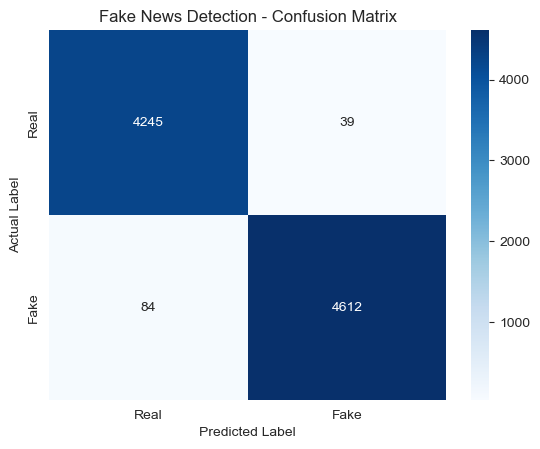

In [26]:

# Import evaluation metrics and plotting libraries
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predict labels for test articles
y_pred = model.predict(X_test_vec)

# Display accuracy as a percentage
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Display precision, recall, F1-score and other metrics
print(classification_report(
    y_test, y_pred,
    target_names=["Real News", "Fake News"]
))

# Create a confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"]
)

# Add chart labels
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()


In [27]:

# Import joblib to save the trained model
import joblib
from pathlib import Path

# Create the models folder if it does not exist
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained model and TF-IDF vectorizer
joblib.dump(model, MODEL_DIR / "fake_news_model.pkl")
joblib.dump(vectorizer, MODEL_DIR / "tfidf_vectorizer.pkl")

# Verify that both files were saved
print("Model saved:", (MODEL_DIR / "fake_news_model.pkl").exists())
print("Vectorizer saved:", (MODEL_DIR / "tfidf_vectorizer.pkl").exists())


Model saved: True
Vectorizer saved: True


In [28]:

# Import regular expressions for text cleaning
import re

# Define the same cleaning function used during preprocessing
def clean_text(text):
    # Convert input into a string
    text = str(text)

    # Replace special characters with spaces
    text = re.sub(r"\W", " ", text)

    # Convert text to lowercase
    text = text.lower()

    # Return cleaned text
    return text


# Define a function to predict whether news is fake or real
def predict_news(news_text):
    # Clean the input news
    cleaned_text = clean_text(news_text)

    # Convert the news into TF-IDF features
    news_vector = vectorizer.transform([cleaned_text])

    # Predict the label: 1 = Fake, 0 = Real
    prediction = model.predict(news_vector)[0]

    # Return a readable result
    if prediction == 1:
        return "Fake News"
    else:
        return "Real News"


# Test the model with a sample news article
sample_news = """
The government announced a new policy to improve education
and provide better digital learning facilities in schools.
"""

# Display the prediction
print("Prediction:", predict_news(sample_news))


Prediction: Fake News


In [29]:

# Count how many Real and Fake articles are present in the test data
from collections import Counter

print("Actual labels:", Counter(y_test))

# Count the labels predicted by the model
print("Predicted labels:", Counter(y_pred))


Actual labels: Counter({1: 4696, 0: 4284})
Predicted labels: Counter({np.int64(1): 4651, np.int64(0): 4329})


In [30]:

# Compare actual and predicted labels
from sklearn.metrics import accuracy_score, classification_report

# Calculate the percentage of correct predictions
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Show precision, recall, and F1-score for each class
print(classification_report(
    y_test,
    y_pred,
    target_names=["Real News", "Fake News"]
))


Accuracy: 98.63 %
              precision    recall  f1-score   support

   Real News       0.98      0.99      0.99      4284
   Fake News       0.99      0.98      0.99      4696

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980

